# Red Neuronal: Predicción de Tipo de Cultivo

**Universidad Autónoma de Nuevo León**  
**Facultad de Ingeniería Mecánica y Eléctrica**  

---

## Producto Integrador de Aprendizaje (PIA)

### **Integrantes:**
* **Marco Antonio Méndez Sánchez** — 2177912
* **Alfonso Uriel Rodriguez Ruiz** — 2177756
* **Daniel Humberto Flores Martínez** — 2177905
* **Jared Nathan Hernandez Garibaldi** — 2177817
* **Gamaliel Cruz Feliciano** — 2173901



### Descripción del Proyecto
Modelo de Red Neuronal para la clasificación y predicción del tipo de cultivo ideal basado en parámetros edafoclimáticos (nutrientes del suelo, clima, precipitación, etc.).

### Librerias 

In [54]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

import numpy as np

### Dataframe Análisis, Limpieza y Correlación de variables

In [38]:
df = pd.read_csv('Crop_recommendation.csv')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [39]:
#Pasar los nombres de las columnas a minusculas y eliminar % 
df.columns = (df.columns.str.lower())

#Eliminar valores nulos
print("Valores nulos por columna:\n", df.isnull().sum())
df = df.dropna() 

#Cuantos tipos de muestras hay por cultivo
print("\nCantidad de muestras por tipo de cultivo:")
print(df['label'].value_counts())

Valores nulos por columna:
 n              0
p              0
k              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Cantidad de muestras por tipo de cultivo:
label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64


In [40]:
df.info

<bound method DataFrame.info of         n   p   k  temperature   humidity        ph    rainfall   label
0      90  42  43    20.879744  82.002744  6.502985  202.935536    rice
1      85  58  41    21.770462  80.319644  7.038096  226.655537    rice
2      60  55  44    23.004459  82.320763  7.840207  263.964248    rice
3      74  35  40    26.491096  80.158363  6.980401  242.864034    rice
4      78  42  42    20.130175  81.604873  7.628473  262.717340    rice
...   ...  ..  ..          ...        ...       ...         ...     ...
2195  107  34  32    26.774637  66.413269  6.780064  177.774507  coffee
2196   99  15  27    27.417112  56.636362  6.086922  127.924610  coffee
2197  118  33  30    24.131797  67.225123  6.362608  173.322839  coffee
2198  117  32  34    26.272418  52.127394  6.758793  127.175293  coffee
2199  104  18  30    23.603016  60.396475  6.779833  140.937041  coffee

[2200 rows x 8 columns]>

In [42]:
# Agrupamos por cultivo y calculamos el promedio de lluvia y temperatura
promedios_por_cultivo = df.groupby('label')[['temperature', 'rainfall']].mean()
print("Promedios climáticos por cultivo:")
print(promedios_por_cultivo)

Promedios climáticos por cultivo:
             temperature    rainfall
label                               
apple          22.630942  112.654779
banana         27.376798  104.626980
blackgram      29.973340   67.884151
chickpea       18.872847   80.058977
coconut        27.409892  175.686646
coffee         25.540477  158.066295
cotton         23.988958   80.398043
grapes         23.849575   69.611829
jute           24.958376  174.792798
kidneybeans    20.115085  105.919778
lentil         24.509052   45.680454
maize          22.389204   84.766988
mango          31.208770   94.704515
mothbeans      28.194920   51.198487
mungbean       28.525775   48.403601
muskmelon      28.663066   24.689952
orange         22.765725  110.474969
papaya         33.723859  142.627839
pigeonpeas     27.741762  149.457564
pomegranate    21.837842  107.528442
rice           23.689332  236.181114
watermelon     25.591767   50.786219


In [43]:
# Creamos una tabla cruzada contando las ocurrencias
relacion_suelo_temp = pd.crosstab(df['label'], df['temperature'])
print("\nRelación entre Cultivo y temperatura:")
print(relacion_suelo_temp)


Relación entre Cultivo y temperatura:
temperature  8.825675   9.467960   9.535586   9.724458   9.851243   9.949929   \
label                                                                           
apple                0          0          0          0          0          0   
banana               0          0          0          0          0          0   
blackgram            0          0          0          0          0          0   
chickpea             0          0          0          0          0          0   
coconut              0          0          0          0          0          0   
coffee               0          0          0          0          0          0   
cotton               0          0          0          0          0          0   
grapes               1          1          1          1          1          1   
jute                 0          0          0          0          0          0   
kidneybeans          0          0          0          0          0    

In [45]:
print(pd.crosstab(df['label'], df['ph']))
# print(pd.crosstab(df['crop'], df['weather_condition']))

ph           3.504752  3.510404  3.525366  3.532009  3.558823  3.692864  \
label                                                                     
apple               0         0         0         0         0         0   
banana              0         0         0         0         0         0   
blackgram           0         0         0         0         0         0   
chickpea            0         0         0         0         0         0   
coconut             0         0         0         0         0         0   
coffee              0         0         0         0         0         0   
cotton              0         0         0         0         0         0   
grapes              0         0         0         0         0         0   
jute                0         0         0         0         0         0   
kidneybeans         0         0         0         0         0         0   
lentil              0         0         0         0         0         0   
maize               0    

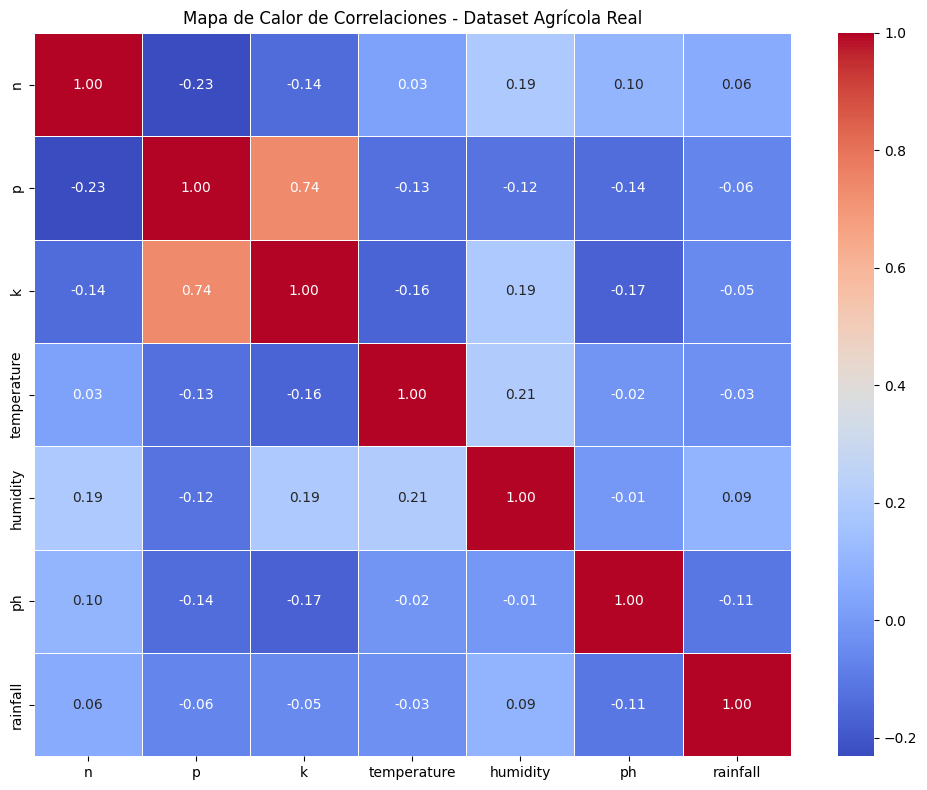

In [49]:
# 1. Seleccionamos solo las columnas numéricas (N, P, K, temp, humedad, etc.)
columnas_num = df.select_dtypes(include=['float64', 'int64'])
# 2. Calculamos la correlación de Pearson
matriz_corr = columnas_num.corr()
# 3. Configuramos el tamaño del gráfico
plt.figure(figsize=(10, 8))
# 4. Dibujamos el Heatmap
# annot=True pone los números dentro de los cuadros
# cmap='coolwarm' usa colores azules (negativa) y rojos (positiva)
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
# Título y mostrar gráfico
plt.title('Mapa de Calor de Correlaciones - Dataset Agrícola Real')
plt.tight_layout()
plt.show()

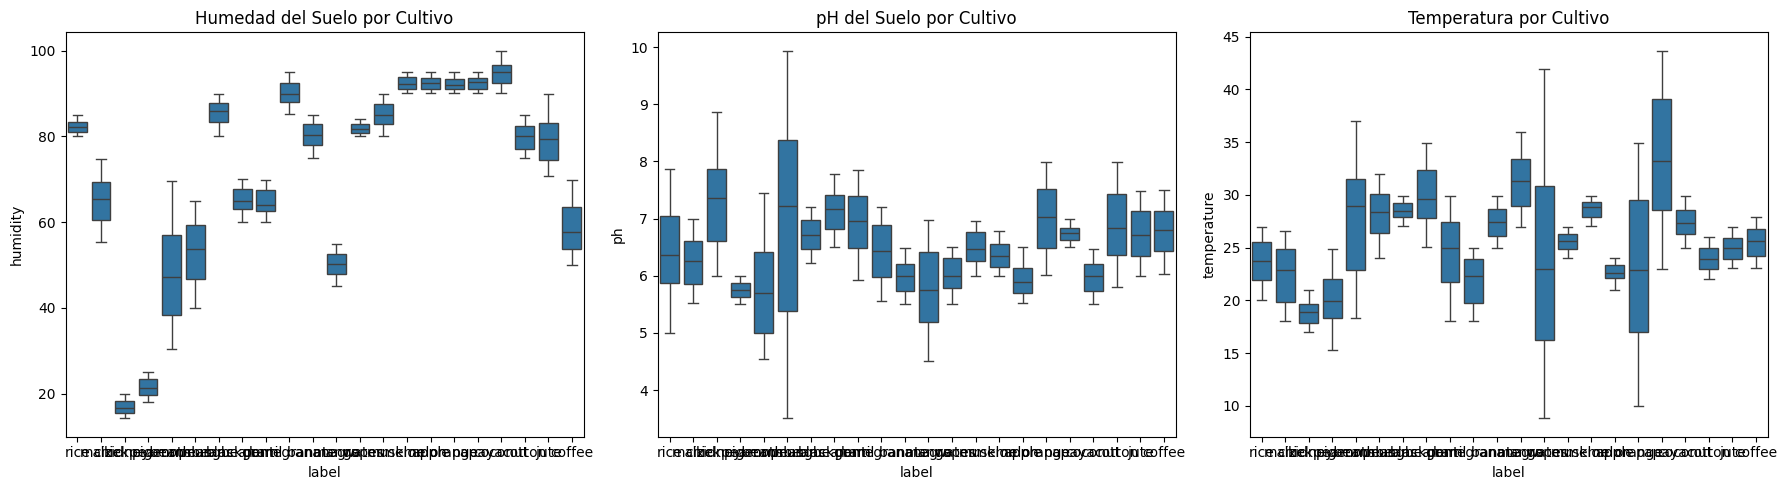

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Gráfico 1: Humedad del Suelo vs Cultivo
sns.boxplot(x='label', y='humidity', data=df, ax=axes[0])
axes[0].set_title('Humedad del Suelo por Cultivo')
# Gráfico 2: pH del Suelo vs Cultivo
sns.boxplot(x='label', y='ph', data=df, ax=axes[1])
axes[1].set_title('pH del Suelo por Cultivo')
# Gráfico 3: Temperatura vs Cultivo
sns.boxplot(x='label', y='temperature', data=df, ax=axes[2])
axes[2].set_title('Temperatura por Cultivo')
plt.tight_layout()
plt.show()

### Preprocesamiento y Red Neuronal

In [ ]:
# Obtener Y y X, Y será la variable objetivo
X = df.drop(columns=['label'])
y = df['label']

# Convertir los nombres de los cultivos a números
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
numero_de_cultivos = len(label_encoder.classes_) 
print(f"Total de cultivos a clasificar: {numero_de_cultivos}")

# Dividir en Entrenamiento y Prueba
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

# Normalizar los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Crear red neuronal
modelo = Sequential([
    # Capa de entrada y Capa oculta 1
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2), 
    
    # Capa oculta 2
    Dense(32, activation='relu'),
    
    # Capa de salida (tantas neuronas como cultivos haya)
    Dense(numero_de_cultivos, activation='softmax')
])

# Compilar y Entrenar
modelo.compile(optimizer='adam', 
               loss='sparse_categorical_crossentropy', 
               metrics=['accuracy'])
print("\n--- INICIANDO EL ENTRENAMIENTO REAL ---")
historial = modelo.fit(X_train_scaled, y_train, 
                       epochs=50, 
                       batch_size=32, 
                       validation_data=(X_test_scaled, y_test))
print("\n--- ENTRENAMIENTO FINALIZADO ---")

Total de cultivos a clasificar: 22

--- INICIANDO EL ENTRENAMIENTO REAL ---


/Users/marcomendezsanchez/miniconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.1358 - loss: 2.8839 - val_accuracy: 0.3136 - val_loss: 2.5888
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4727 - loss: 2.2428 - val_accuracy: 0.5864 - val_loss: 1.8852
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6199 - loss: 1.5428 - val_accuracy: 0.7159 - val_loss: 1.2079
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7636 - loss: 1.0233 - val_accuracy: 0.8045 - val_loss: 0.8045
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8358 - loss: 0.7140 - val_accuracy: 0.8455 - val_loss: 0.5997
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8472 - loss: 0.5802 - val_accuracy: 0.8795 - val_loss: 0.4777
Epoch 7/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8841 - loss: 0.4612 - val_accuracy: 0.8955 - val_loss: 0.4012
Epoch 8/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8989 - loss: 0.3942 - val_accuracy: 0.9182 - val_loss:

### Predicción

In [53]:
def recomendar_cultivo(N, P, K, temperatura, humedad, ph, lluvia):
    # 1. Ponemos los datos en el formato que espera el escalador (una fila, 7 columnas)
    datos_nuevos = np.array([[N, P, K, temperatura, humedad, ph, lluvia]])
    
    # Normalizar los datos igual que en el entrenamiento
    datos_escalados = scaler.transform(datos_nuevos)
    
    # 3. Pedirle a la Red Neuronal que haga la predicción (devuelve probabilidades)
    prediccion_probabilidades = modelo.predict(datos_escalados)
    
    # 4. Buscar cuál cultivo obtuvo el porcentaje más alto de probabilidad
    indice_ganador = np.argmax(prediccion_probabilidades)
    
    # 5. Traducir el número ganador (ej. 3) a texto (ej. 'cafe')
    cultivo_recomendado = label_encoder.inverse_transform([indice_ganador])
    
    return cultivo_recomendado[0]

# Simulación para Monterrey
# Valores: N=20, P=120, K=200, Temp=24°C, Humedad=80%, pH=6.0, Lluvia=200mm
resultado = recomendar_cultivo(30, 45, 80, 28.5, 60.0, 7.8, 550.0)
print("\n=============================================")
print(f"EL CULTIVO ÓPTIMO RECOMENDADO ES: {resultado.upper()}")
print("=============================================")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

EL CULTIVO ÓPTIMO RECOMENDADO ES: RICE


/Users/marcomendezsanchez/miniconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
